# Project 2: Exploratory Data Analysis (EDA)
**Dataset:** Dataset for Data Analytics (1,200 orders)
**Goal:** Understand patterns, trends and distributions in the order data.
**Tools:** Python, pandas, matplotlib

## Import Libraries and Load Data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_excel("Dataset for Data Analytics .xlsx")
df.head()

C:\Users\spectre\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\spectre\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04


## Data Overview
- Checking the size, column types, missing values and duplicates.

In [2]:
df.shape

(1200, 14)

In [3]:
df.columns.tolist()

['OrderID',
 'Date',
 'CustomerID',
 'Product',
 'Quantity',
 'UnitPrice',
 'ShippingAddress',
 'PaymentMethod',
 'OrderStatus',
 'TrackingNumber',
 'ItemsInCart',
 'CouponCode',
 'ReferralSource',
 'TotalPrice']

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   OrderID          1200 non-null   str           
 1   Date             1200 non-null   datetime64[us]
 2   CustomerID       1200 non-null   str           
 3   Product          1200 non-null   str           
 4   Quantity         1200 non-null   int64         
 5   UnitPrice        1200 non-null   float64       
 6   ShippingAddress  1200 non-null   str           
 7   PaymentMethod    1200 non-null   str           
 8   OrderStatus      1200 non-null   str           
 9   TrackingNumber   1200 non-null   str           
 10  ItemsInCart      1200 non-null   int64         
 11  CouponCode       891 non-null    str           
 12  ReferralSource   1200 non-null   str           
 13  TotalPrice       1200 non-null   float64       
dtypes: datetime64[us](1), float64(2), int64(2), str(9)


In [5]:
df.isnull().sum()

OrderID              0
Date                 0
CustomerID           0
Product              0
Quantity             0
UnitPrice            0
ShippingAddress      0
PaymentMethod        0
OrderStatus          0
TrackingNumber       0
ItemsInCart          0
CouponCode         309
ReferralSource       0
TotalPrice           0
dtype: int64

In [6]:
df.duplicated().sum()

0

## Basic Statistics
Mean, median and count for the numeric and category columns.

In [7]:
df[["Quantity", "UnitPrice", "ItemsInCart", "TotalPrice"]].describe()

,Quantity,UnitPrice,ItemsInCart,TotalPrice
count,1200.000000,1200.000000,1200.000000,1200.000000
mean,2.945833,356.412750,5.485000,1053.968300
std,1.407557,197.177146,2.281983,819.856558
min,1.000000,11.390000,1.000000,11.390000
25%,2.000000,186.062500,4.000000,410.520000
50%,3.000000,364.210000,5.000000,823.615000
75%,4.000000,521.570000,7.000000,1578.475000
max,5.000000,699.930000,10.000000,3456.400000


In [8]:
print("Mean:", df["TotalPrice"].mean())
print("Median:",df["TotalPrice"].median())
print("Count:",df["TotalPrice"].count())

Mean: 1053.9683
Median: 823.615
Count: 1200


In [9]:
df["Product"].value_counts()

Product
Printer    181
Tablet     179
Chair      178
Laptop     173
Desk       170
Monitor    163
Phone      156
Name: count, dtype: int64

In [10]:
df["OrderStatus"].value_counts()

OrderStatus
Cancelled    250
Returned     247
Pending      237
Shipped      235
Delivered    231
Name: count, dtype: int64

## Distributions
Looking for the shape of TotalPrice and Unitprice

<function matplotlib.pyplot.show(close=None, block=None)>

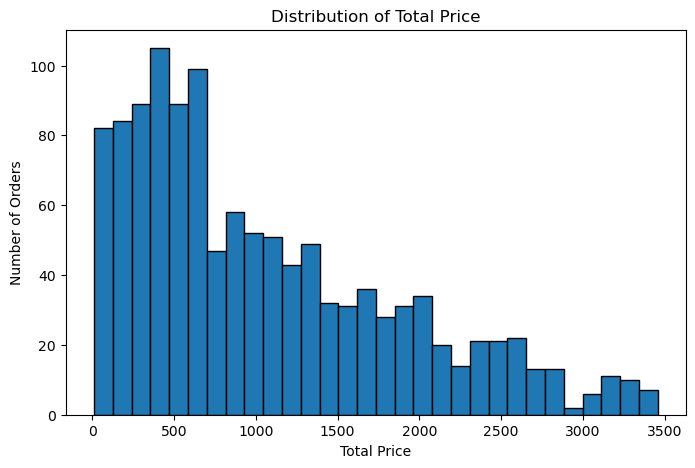

In [11]:
plt.figure(figsize=(8, 5))
plt.hist(df["TotalPrice"], bins=30, edgecolor="black")
plt.title("Distribution of Total Price")
plt.xlabel("Total Price")
plt.ylabel("Number of Orders")
plt.show

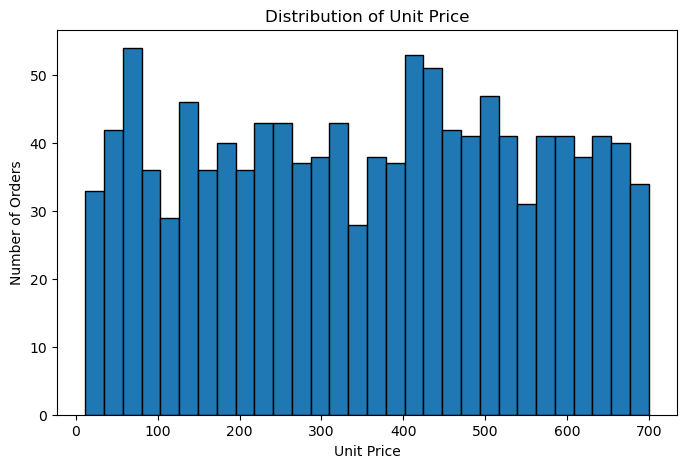

In [12]:
plt.figure(figsize=(8, 5))
plt.hist(df["UnitPrice"], bins=30, edgecolor="black")
plt.title("Distribution of Unit Price")
plt.xlabel("Unit Price")
plt.ylabel("Number of Orders")
plt.show()

## Trends
Orders and revenue over time, and revenue by product.

In [13]:
df["YearMonth"] = df["Date"].dt.to_period("M")

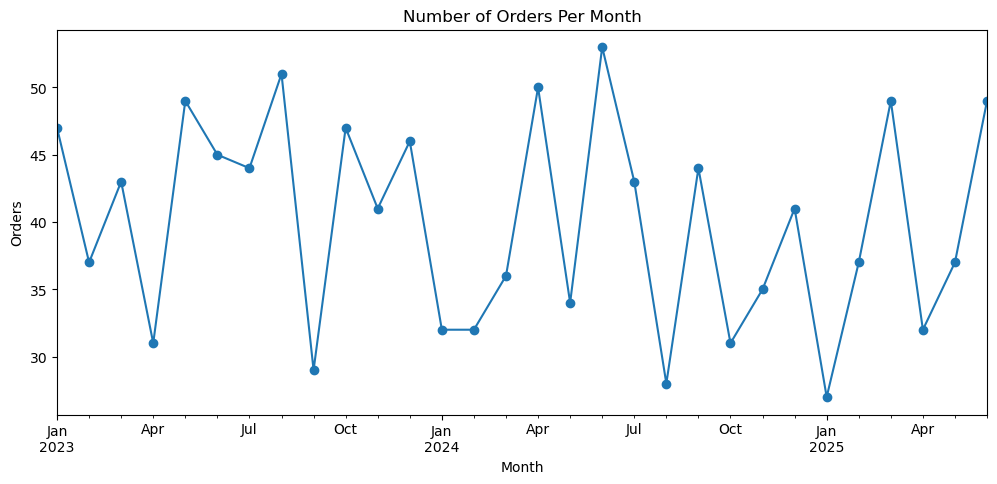

In [14]:
monthly_orders = df.groupby("YearMonth")["OrderID"].count()

plt.figure(figsize=(12, 5))
monthly_orders.plot(kind="line", marker="o")
plt.title("Number of Orders Per Month")
plt.xlabel("Month")
plt.ylabel("Orders")
plt.show()

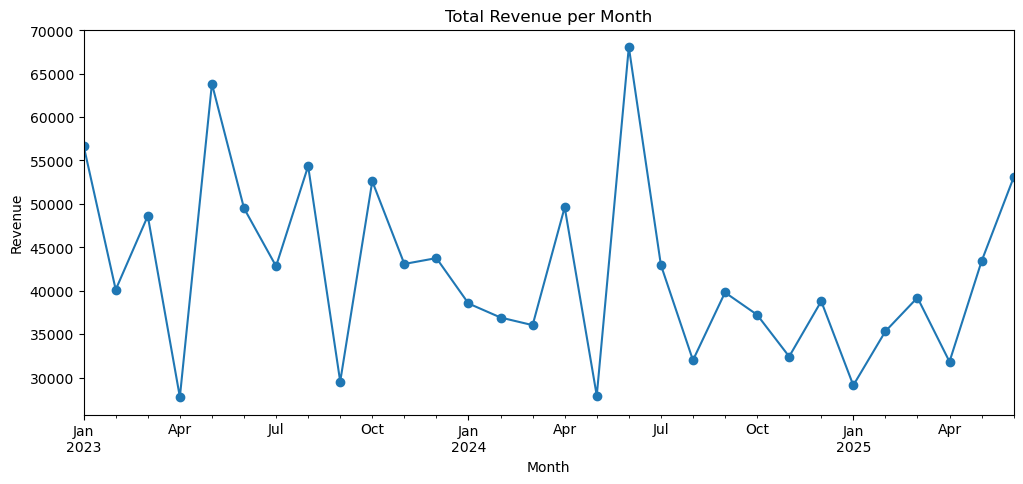

In [15]:
monthly_revenue = df.groupby("YearMonth")["TotalPrice"].sum()

plt.figure(figsize=(12, 5))
monthly_revenue.plot(kind="line", marker="o")
plt.title("Total Revenue per Month")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.show()

In [16]:
df.groupby("Product")["TotalPrice"].agg(["count", "sum", "mean", "median"]).sort_values("sum", ascending=False)

,count,sum,mean,median
Product,,,,
Chair,178,195620.11,1098.989382,928.575
Printer,181,195612.61,1080.732652,857.400
Laptop,173,192126.56,1110.558150,915.640
Tablet,179,186568.95,1042.284637,786.660
Monitor,163,175651.41,1077.616012,853.400
Desk,170,167459.93,985.058412,784.390
Phone,156,151722.39,972.579423,691.715


## Outliers
using boxplot and the IQR rule to find unusually large orders.

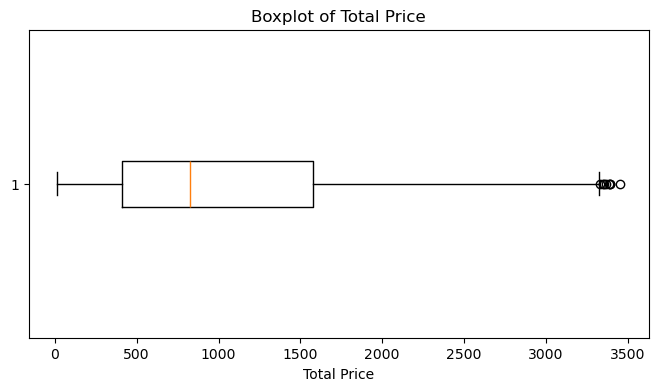

In [17]:
plt.figure(figsize=(8, 4))
plt.boxplot(df["TotalPrice"], vert=False)
plt.title("Boxplot of Total Price")
plt.xlabel("Total Price")
plt.show()

In [18]:
Q1 = df["TotalPrice"].quantile(0.25)
Q3 = df["TotalPrice"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Lower limit:", lower)
print("Upper limit:", upper)

outliers = df[(df["TotalPrice"] < lower) | (df["TotalPrice"] > upper)]
print("Number of outliers:", len(outliers))
outliers[["OrderID", "Product", "Quantity", "UnitPrice", "TotalPrice"]]

Lower limit: -1341.4125
Upper limit: 3330.4075
Number of outliers: 8


,OrderID,Product,Quantity,UnitPrice,TotalPrice
107,ORD200107,Printer,5,670.75,3353.75
326,ORD200326,Laptop,5,670.48,3352.40
328,ORD200328,Tablet,5,674.04,3370.20
469,ORD200469,Chair,5,676.98,3384.90
632,ORD200632,Laptop,5,678.16,3390.80
789,ORD200789,Tablet,5,691.28,3456.40
1065,ORD201065,Printer,5,666.80,3334.00
1122,ORD201122,Monitor,5,678.19,3390.95


In [19]:
df["CouponCode"] = df["CouponCode"].fillna("No Coupon")

In [20]:
df["CouponCode"].value_counts()

CouponCode
FREESHIP     313
No Coupon    309
WINTER15     292
SAVE10       286
Name: count, dtype: int64

## Key Observations

**1. Dataset overview**
- The dataset has 1200 orders and 14 columns.
- There are no duplicate rows. Only CouponCode had missing values (309). I labelled these "No Coupon", because blanks means no coupon was used.

**2. Basic Statistics**
- The average order value (TotalPrice) is about 1054 but the median is about 824.
- The mean is higher than the median, so a few large orders pull the average up. The median is a better measure of a typical order.

**3. Distributions**
- TotalPrice is piled up on the left with a tail to the right (right-skewed).
- UnitPrice is spread fairly evenly between about 11 and 700.

**4. Trends**
- Monthly orders and revenue go up and down with no clear long-term increase or decrease.
- Product revenue: Chair earns the most (about 195,620) and Phone earns the least (about 151,722).
- 41% of orders are Cancelled or Returned, Only 19% are Delivered.

**5. outliers**
- Using the IQR rule (upper limit about 3,330), I found 8 Outliers.
- All of them have Quantity = 5 and a high unit price. They are real bulk purchases, so I kept them.

**6. Conclusion**
- The business has steady sales but a very high return and cancellation rate, which is the biggest area to investigate.